# NHTS 2022: Column Clustering and Research Directions

This notebook complements the existing correlation notebook. It groups **columns**, then compares candidate research questions across commute trips, all employed adults, and households. Existing source files are preserved.

Use the installed **Python 3 (ipykernel)** Anaconda environment. Outputs go to `research_directions/`. These are unweighted exploratory associations, not causal effects or national population estimates.

In [1]:
from pathlib import Path
import io
from contextlib import redirect_stdout
import pandas as pd
from IPython.display import display, Image
from NHTS_2022_research_directions import run_analysis, research_questions, OUT

with redirect_stdout(io.StringIO()):
    samples, associations, summary = run_analysis()
display(pd.Series(summary['counts'], name='Count').to_frame())

,Count
commute_trips,4269
commuter_people,2384
commuter_households,1928
adult_workers,7689
households,7893


## Methods

Spearman rho is used for numerical and ordered variables, including density bands, income, education and telework categories. Bias-corrected Cramer's V is used for nominal pairs. Rank eta measures unsigned separation of numerical ranks among categories. These measures are not interchangeable.

Columns are clustered separately by type with average linkage and dissimilarity `1 - abs(rho)` or `1 - V`. The displayed distance cut is 0.45; membership at 0.30 and 0.60 is also exported. This is exploratory grouping, not an automatically chosen optimal number of clusters.

Special codes -1, -7, -8 and -9 are excluded, with no automatic zero recoding for skips. Pairwise complete observations are used. At least 100 complete pairs are required for Spearman. Survey-imputed income is retained as `HHFAMINC_IMP`; this analysis does not impute other values.

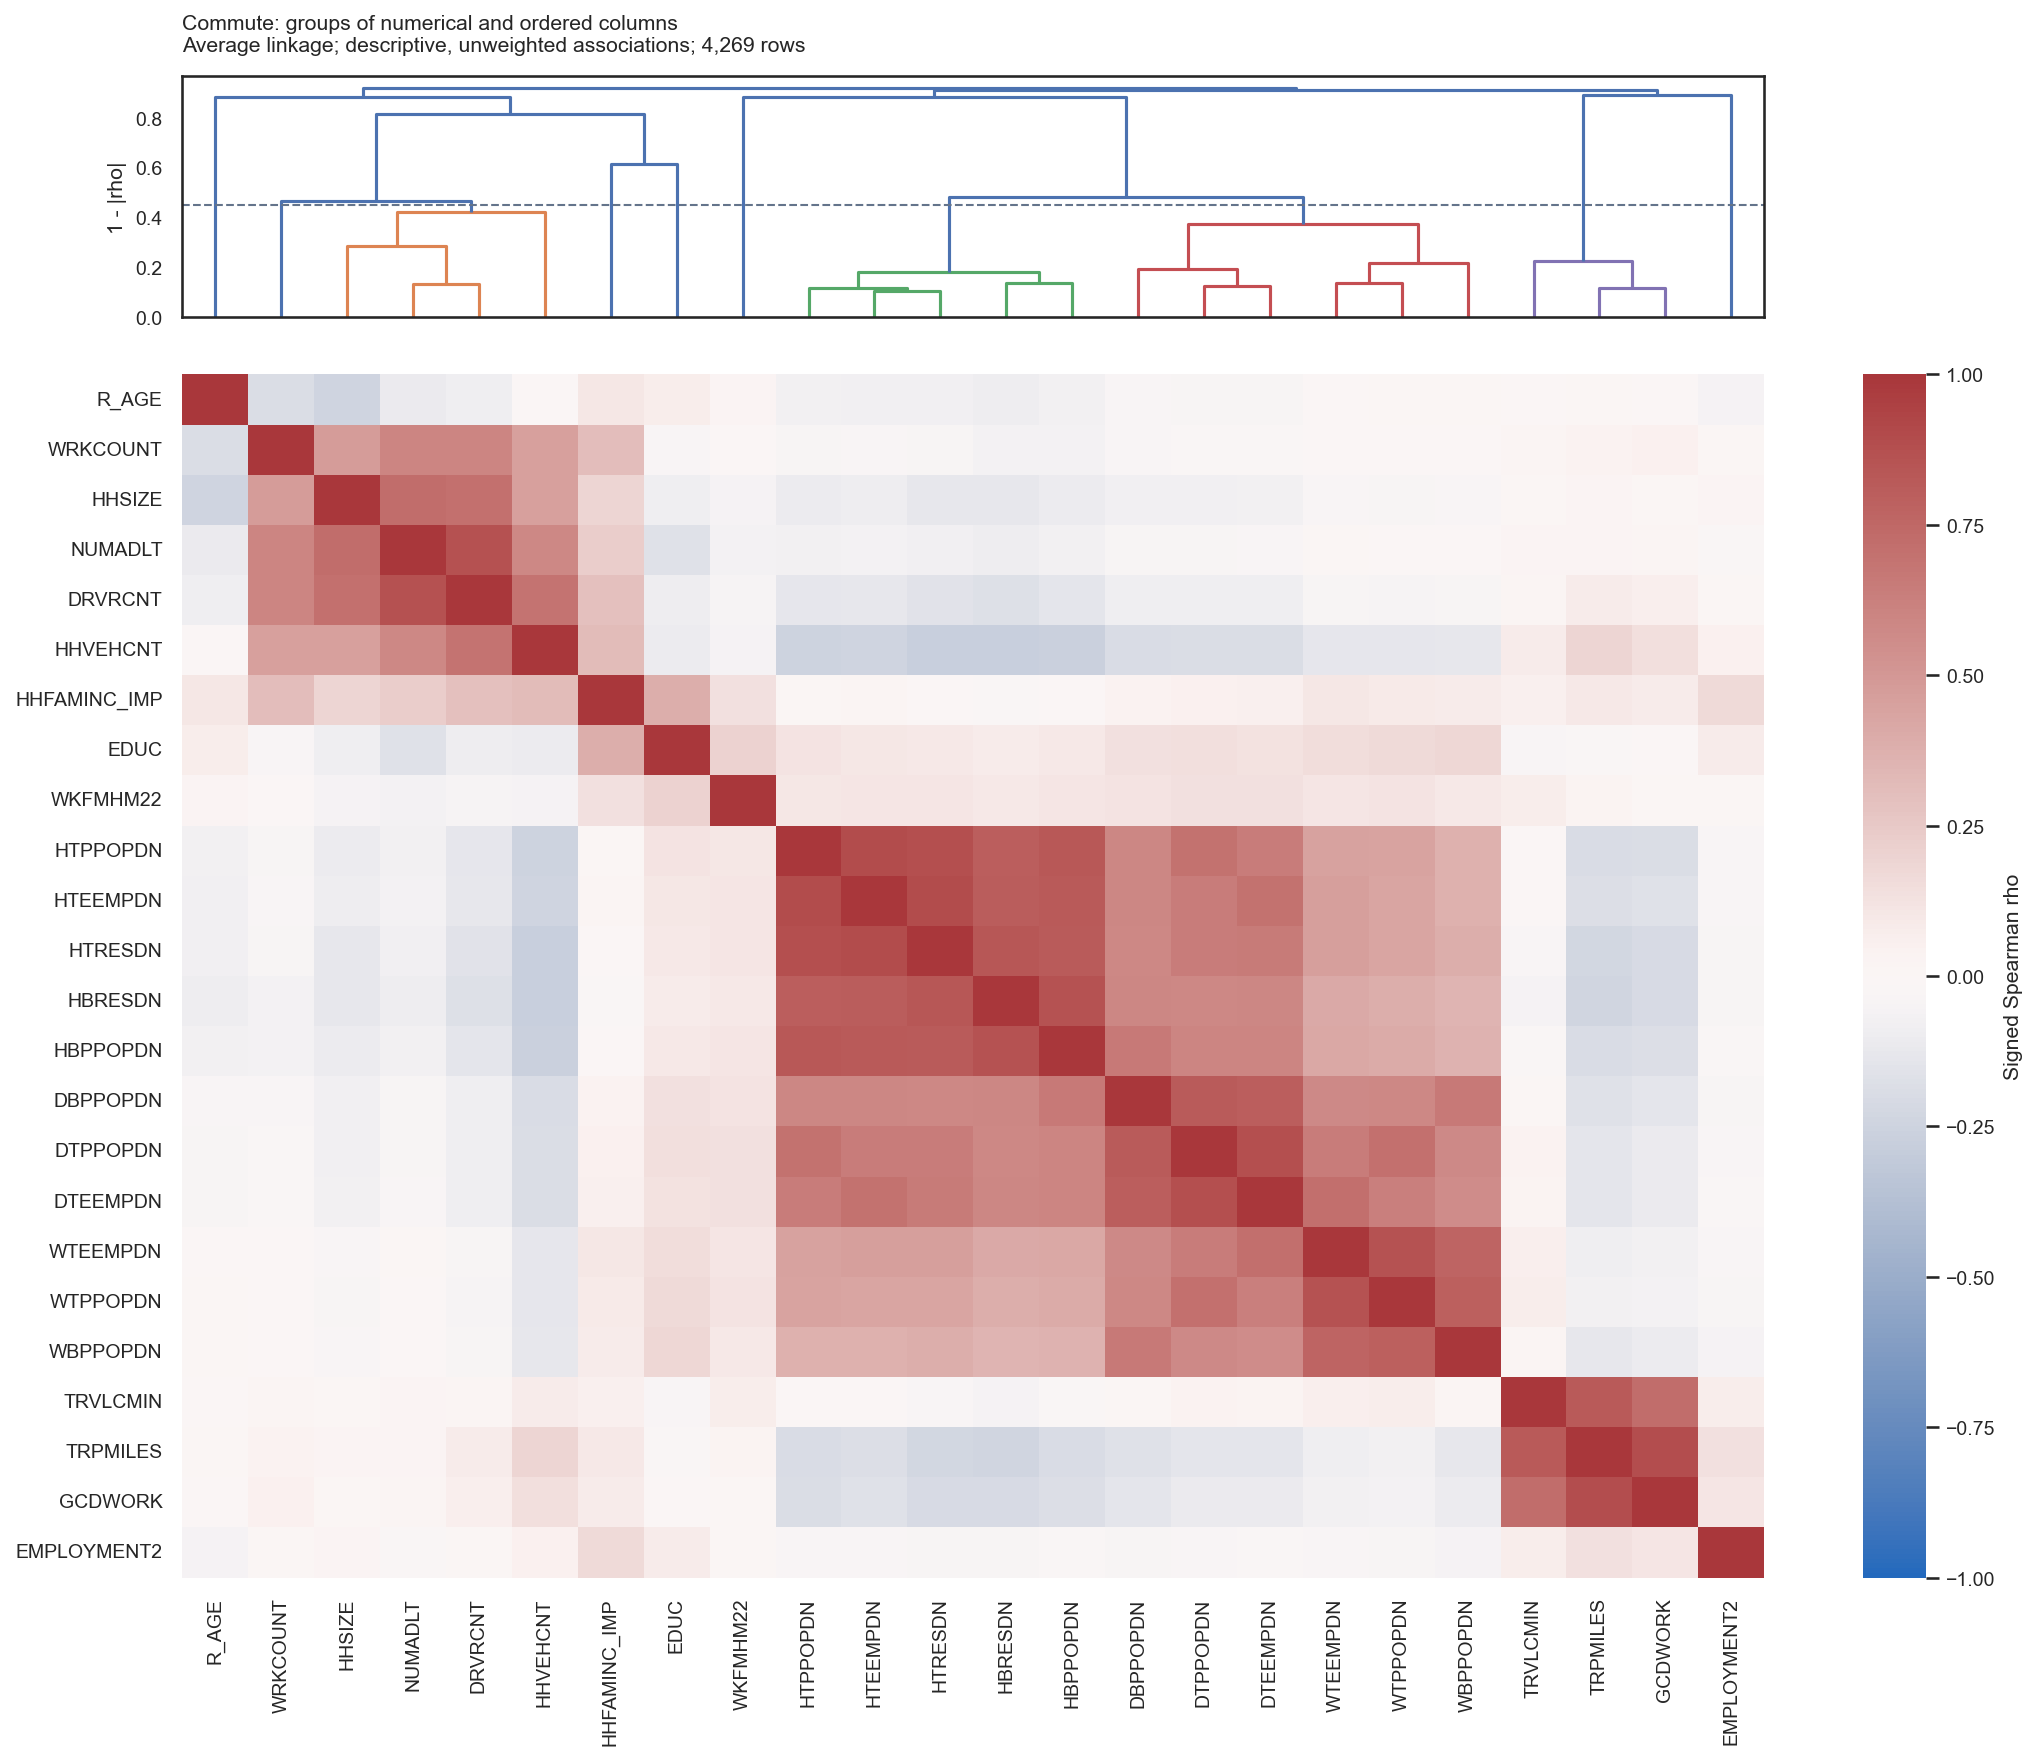

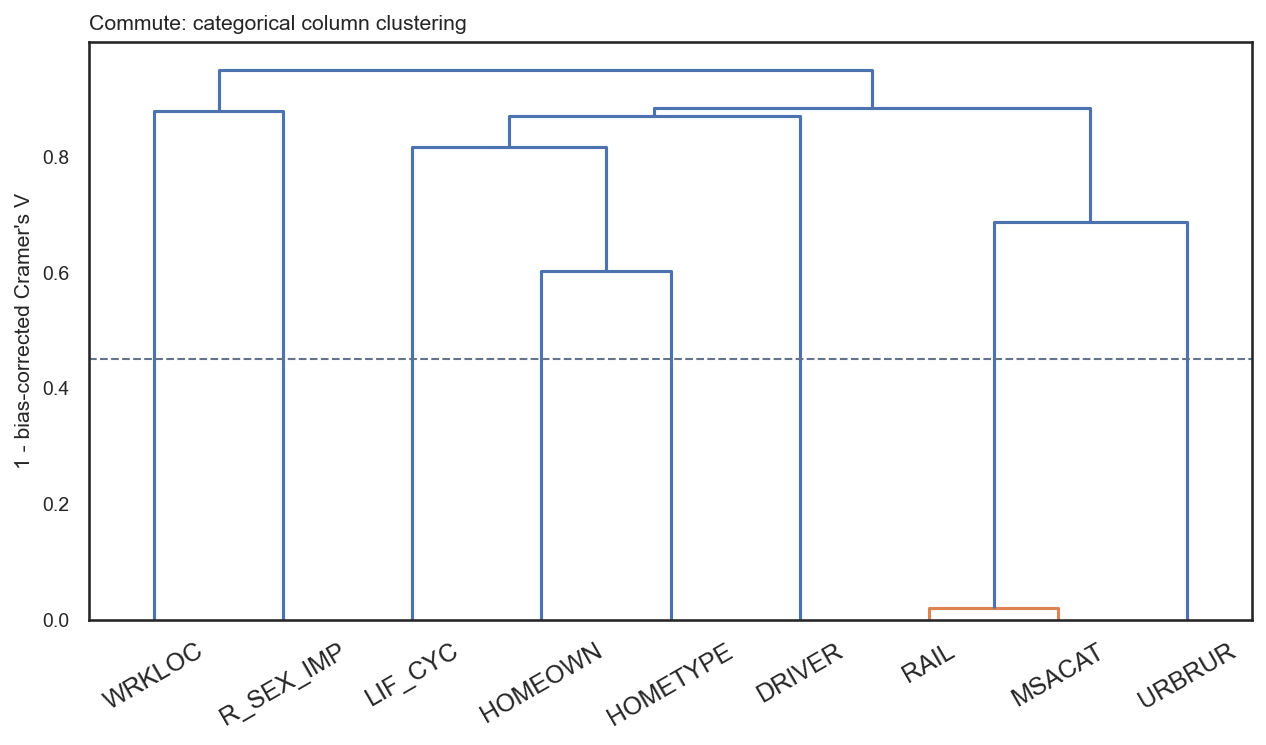

In [2]:
display(Image(filename=str(OUT / 'commute_column_clusters.png')))
display(Image(filename=str(OUT / 'commute_categorical_clusters.png')))

In [3]:
members = samples['commute']['clusters'].query('distance_cut == 0.45')
display(members.groupby(['association', 'cluster'])['column'].agg(', '.join).to_frame('Columns'))

Columns
association               cluster                                                   
absolute Spearman         1                       HHSIZE, NUMADLT, DRVRCNT, HHVEHCNT
                          2                                                 WRKCOUNT
                          3                                             HHFAMINC_IMP
                          4                                                     EDUC
                          5                                                    R_AGE
                          6           HBPPOPDN, HTPPOPDN, HBRESDN, HTRESDN, HTEEMPDN
                          7        WBPPOPDN, WTPPOPDN, WTEEMPDN, DBPPOPDN, DTPPOP...
                          8                                                 WKFMHM22
                          9                              GCDWORK, TRPMILES, TRVLCMIN
                          10                                             EMPLOYMENT2
bias-corrected Cramer's V 1                                                   WRKLOC
                          2                                                R_SEX_IMP
                          3                                                  HOMEOWN
                          4                                                 HOMETYPE
                          5                                                  LIF_CYC
                          6                                                   DRIVER
                          7                                             RAIL, MSACAT
                          8                                                   URBRUR

## What the groups mean

The current sample groups residential-density measurements together, workplace/destination-density measurements together, household size/adults/drivers/vehicles together, and commute distance/time together. Rail status and MSA category overlap by construction. Income, education, age, work hours and telework remain singletons at this cut; they can still be useful.

**Destination is not always workplace:** home-based work trips include trips toward home. The DB*/DT* fields identify a trip's destination, while W* fields identify the person's workplace.

In [4]:
for name, rows in summary['selected_correlations'].items():
    print(name.upper())
    display(pd.DataFrame(rows).rename(columns={'a':'Column 1','b':'Column 2','rho':'Spearman rho','n':'Pair n'}))

COMMUTE


,Column 1,Column 2,Spearman rho,Pair n
0,TRPMILES,TRVLCMIN,0.826427,4266
1,GCDWORK,TRVLCMIN,0.726494,3811
2,GCDWORK,TRPMILES,0.884300,3813
3,HBPPOPDN,HBRESDN,0.865591,4199
4,HBPPOPDN,HTPPOPDN,0.834701,4237
5,HHVEHCNT,DRVRCNT,0.691073,4269
6,HHSIZE,NUMADLT,0.721934,4269
7,HHFAMINC_IMP,EDUC,0.384155,4269
8,HBPPOPDN,HHVEHCNT,-0.268341,4250


HOUSEHOLD


,Column 1,Column 2,Spearman rho,Pair n
0,HHVEHCNT,HHFAMINC_IMP,0.391217,7893
1,HHVEHCNT,DRVRCNT,0.695974,7893
2,HHVEHCNT,HBPPOPDN,-0.244914,7855


WORKERS


,Column 1,Column 2,Spearman rho,Pair n
0,WKFMHM22,EDUC,0.266886,7689
1,WKFMHM22,HHFAMINC_IMP,0.217347,7689
2,WKFMHM22,CNTTDTR,-0.062301,7689
3,GCDWORK,HBPPOPDN,-0.183202,5633
4,GCDWORK,HHFAMINC_IMP,0.106004,5665


## Several research questions

Directions 1 and 2 extend the current mode-choice project. Direction 3 is the clearest numerical-regression alternative. Directions 4 and 5 use broader, correctly defined household/person samples. Directions 6 and 7 have more modest marginal evidence. The correlations help assess feasibility; subject knowledge and a literature review remain necessary.

In [5]:
questions = research_questions()
for _, q in questions.iterrows():
    display(pd.DataFrame({'Item':q.index, 'Details':q.values}))

,Item,Details
0,Direction,1. Vehicle access and mode choice
1,Question,Among adults making weekday home-based work tr...
2,Outcome,mode_3cat
3,Main columns,"HHVEHCNT, DRIVER; adjust for GCDWORK, HHFAMINC..."
4,Model family,Categorical outcome / multinomial logistic reg...
5,Sample,"4,269 trips; 207 non-car trips"
6,Evidence,DRIVER vs mode: V=0.505; HHVEHCNT vs mode: ran...
7,Assessment,Strong direct continuation of the current proj...


,Item,Details
0,Direction,2. Residential environment and mode
1,Question,How are residential density and metropolitan h...
2,Outcome,mode_3cat
3,Main columns,"HTRESDN or HBPPOPDN, RAIL or MSACAT; adjust fo..."
4,Model family,Categorical outcome / multinomial logistic reg...
5,Sample,"4,269 trips"
6,Evidence,"HTRESDN vs mode: rank eta=0.254 (n=4,236); RAI..."
7,Assessment,Useful planning question. RAIL is metropolitan...


,Item,Details
0,Direction,3. Commute duration
1,Question,"How are home-work distance, transport mode, an..."
2,Outcome,TRVLCMIN (minutes)
3,Main columns,"GCDWORK, mode_3cat, RAIL or MSACAT; optional a..."
4,Model family,Numerical outcome / suitable positive-outcome ...
5,Sample,"4,266 trips with duration; 3,811 also have GCD..."
6,Evidence,GCDWORK vs duration: rho=0.726; actual trip mi...
7,Assessment,Clearest numerical-regression alternative. For...


,Item,Details
0,Direction,4. Household vehicle ownership
1,Question,"How are household income, residential density,..."
2,Outcome,HHVEHCNT (vehicle count)
3,Main columns,"HHFAMINC_IMP, HBPPOPDN, DRVRCNT or NUMADLT, HO..."
4,Model family,"Count regression, such as Poisson or negative ..."
5,Sample,"7,893 households, including 476 with no vehicles"
6,Evidence,Vehicle count vs income: rho=0.391; vs home de...
7,Assessment,Strong distinct question with one record per h...


,Item,Details
0,Direction,5. Telework and socioeconomic characteristics
1,Question,"Among employed adults, how are education, hous..."
2,Outcome,WKFMHM22 (four ordered categories)
3,Main columns,"EDUC, HHFAMINC_IMP, R_AGE, one home-density me..."
4,Model family,Ordinal logistic regression; binary any telewo...
5,Sample,"7,689 employed adults; all have WKFMHM22"
6,Evidence,Telework vs education: rho=0.267; vs income: r...
7,Assessment,Strong separate direction with a larger person...


,Item,Details
0,Direction,6. Residential environment and commute length
1,Question,Among employed adults with an observed home-wo...
2,Outcome,GCDWORK (great-circle miles)
3,Main columns,"HBPPOPDN or HBRESDN, HHFAMINC_IMP, R_AGE, EDUC..."
4,Model family,Numerical outcome / distance regression or qua...
5,Sample,"5,665 of 7,689 employed adults have GCDWORK"
6,Evidence,"Home density vs distance: rho=-0.183 (n=5,633)..."
7,Assessment,Feasible but relationships are modest. Missing...


,Item,Details
0,Direction,7. Telework and daily travel (tentative)
1,Question,Is usual telework frequency associated with th...
2,Outcome,CNTTDTR (daily trip count)
3,Main columns,"WKFMHM22, EDUC, R_AGE, household composition; ..."
4,Model family,"Count regression, with dispersion and excess-z..."
5,Sample,"7,689 employed adults, including non-travellers"
6,Evidence,Telework vs daily trip count: rho=-0.062
7,Assessment,Weak marginal signal; lower priority. Usual te...


## Candidate outcome associations

Tables below are descriptive comparisons, not final predictor lists. If mode is the outcome, omit realised duration and realised trip miles as ordinary pre-choice predictors. If distance is the outcome, do not explain it with another measurement of the same realised journey. Work-location category overlaps telework by definition and should not serve as an ordinary predictor of telework frequency.

In [6]:
for name, result in associations.items():
    print(name.upper())
    display(result.drop(columns='absolute_value'))

COMMUTE


,outcome,predictor,measure,value,n
89,GCDWORK,URBRUR,Rank eta,0.186580,3813
91,GCDWORK,HOMEOWN,Rank eta,0.138009,3813
94,GCDWORK,DRIVER,Rank eta,0.136072,3813
93,GCDWORK,HOMETYPE,Rank eta,0.135118,3813
90,GCDWORK,MSACAT,Rank eta,0.102013,3813
...,...,...,...,...,...
22,mode_3cat,EMPLOYMENT2,Rank eta,0.050255,4136
0,mode_3cat,HHSIZE,Rank eta,0.047096,4269
1,mode_3cat,NUMADLT,Rank eta,0.035861,4269
3,mode_3cat,WRKCOUNT,Rank eta,0.028802,4269


HOUSEHOLD


,outcome,predictor,measure,value,n
14,HHVEHCNT,LIF_CYC,Rank eta,0.561089,7893
15,HHVEHCNT,HOMETYPE,Rank eta,0.443243,7893
13,HHVEHCNT,HOMEOWN,Rank eta,0.374971,7893
11,HHVEHCNT,URBRUR,Rank eta,0.179999,7893
12,HHVEHCNT,MSACAT,Rank eta,0.113504,7893
10,HHVEHCNT,RAIL,Rank eta,0.093742,7893
2,HHVEHCNT,DRVRCNT,Spearman rho,0.695974,7893
1,HHVEHCNT,NUMADLT,Spearman rho,0.574236,7893
0,HHVEHCNT,HHSIZE,Spearman rho,0.496034,7893
9,HHVEHCNT,HHFAMINC_IMP,Spearman rho,0.391217,7893


WORKERS


,outcome,predictor,measure,value,n
53,CNTTDTR,WRKLOC,Rank eta,0.095876,7689
51,CNTTDTR,DRIVER,Rank eta,0.085550,7689
50,CNTTDTR,LIF_CYC,Rank eta,0.058530,7689
49,CNTTDTR,HOMEOWN,Rank eta,0.046700,7689
48,CNTTDTR,MSACAT,Rank eta,0.032647,7689
46,CNTTDTR,RAIL,Rank eta,0.028620,7689
47,CNTTDTR,URBRUR,Rank eta,0.022265,7689
52,CNTTDTR,R_SEX_IMP,Rank eta,0.006007,7689
42,CNTTDTR,EDUC,Spearman rho,0.134475,7689
28,CNTTDTR,NUMADLT,Spearman rho,-0.088960,7689


## Other samples and quality

The full household sample avoids counting the same household once per commute trip. The employed-adult sample includes workers with no observed commute. Great-circle distance is observed for 5,665 of 7,689 employed adults; inapplicable work locations change the population represented by a distance analysis.

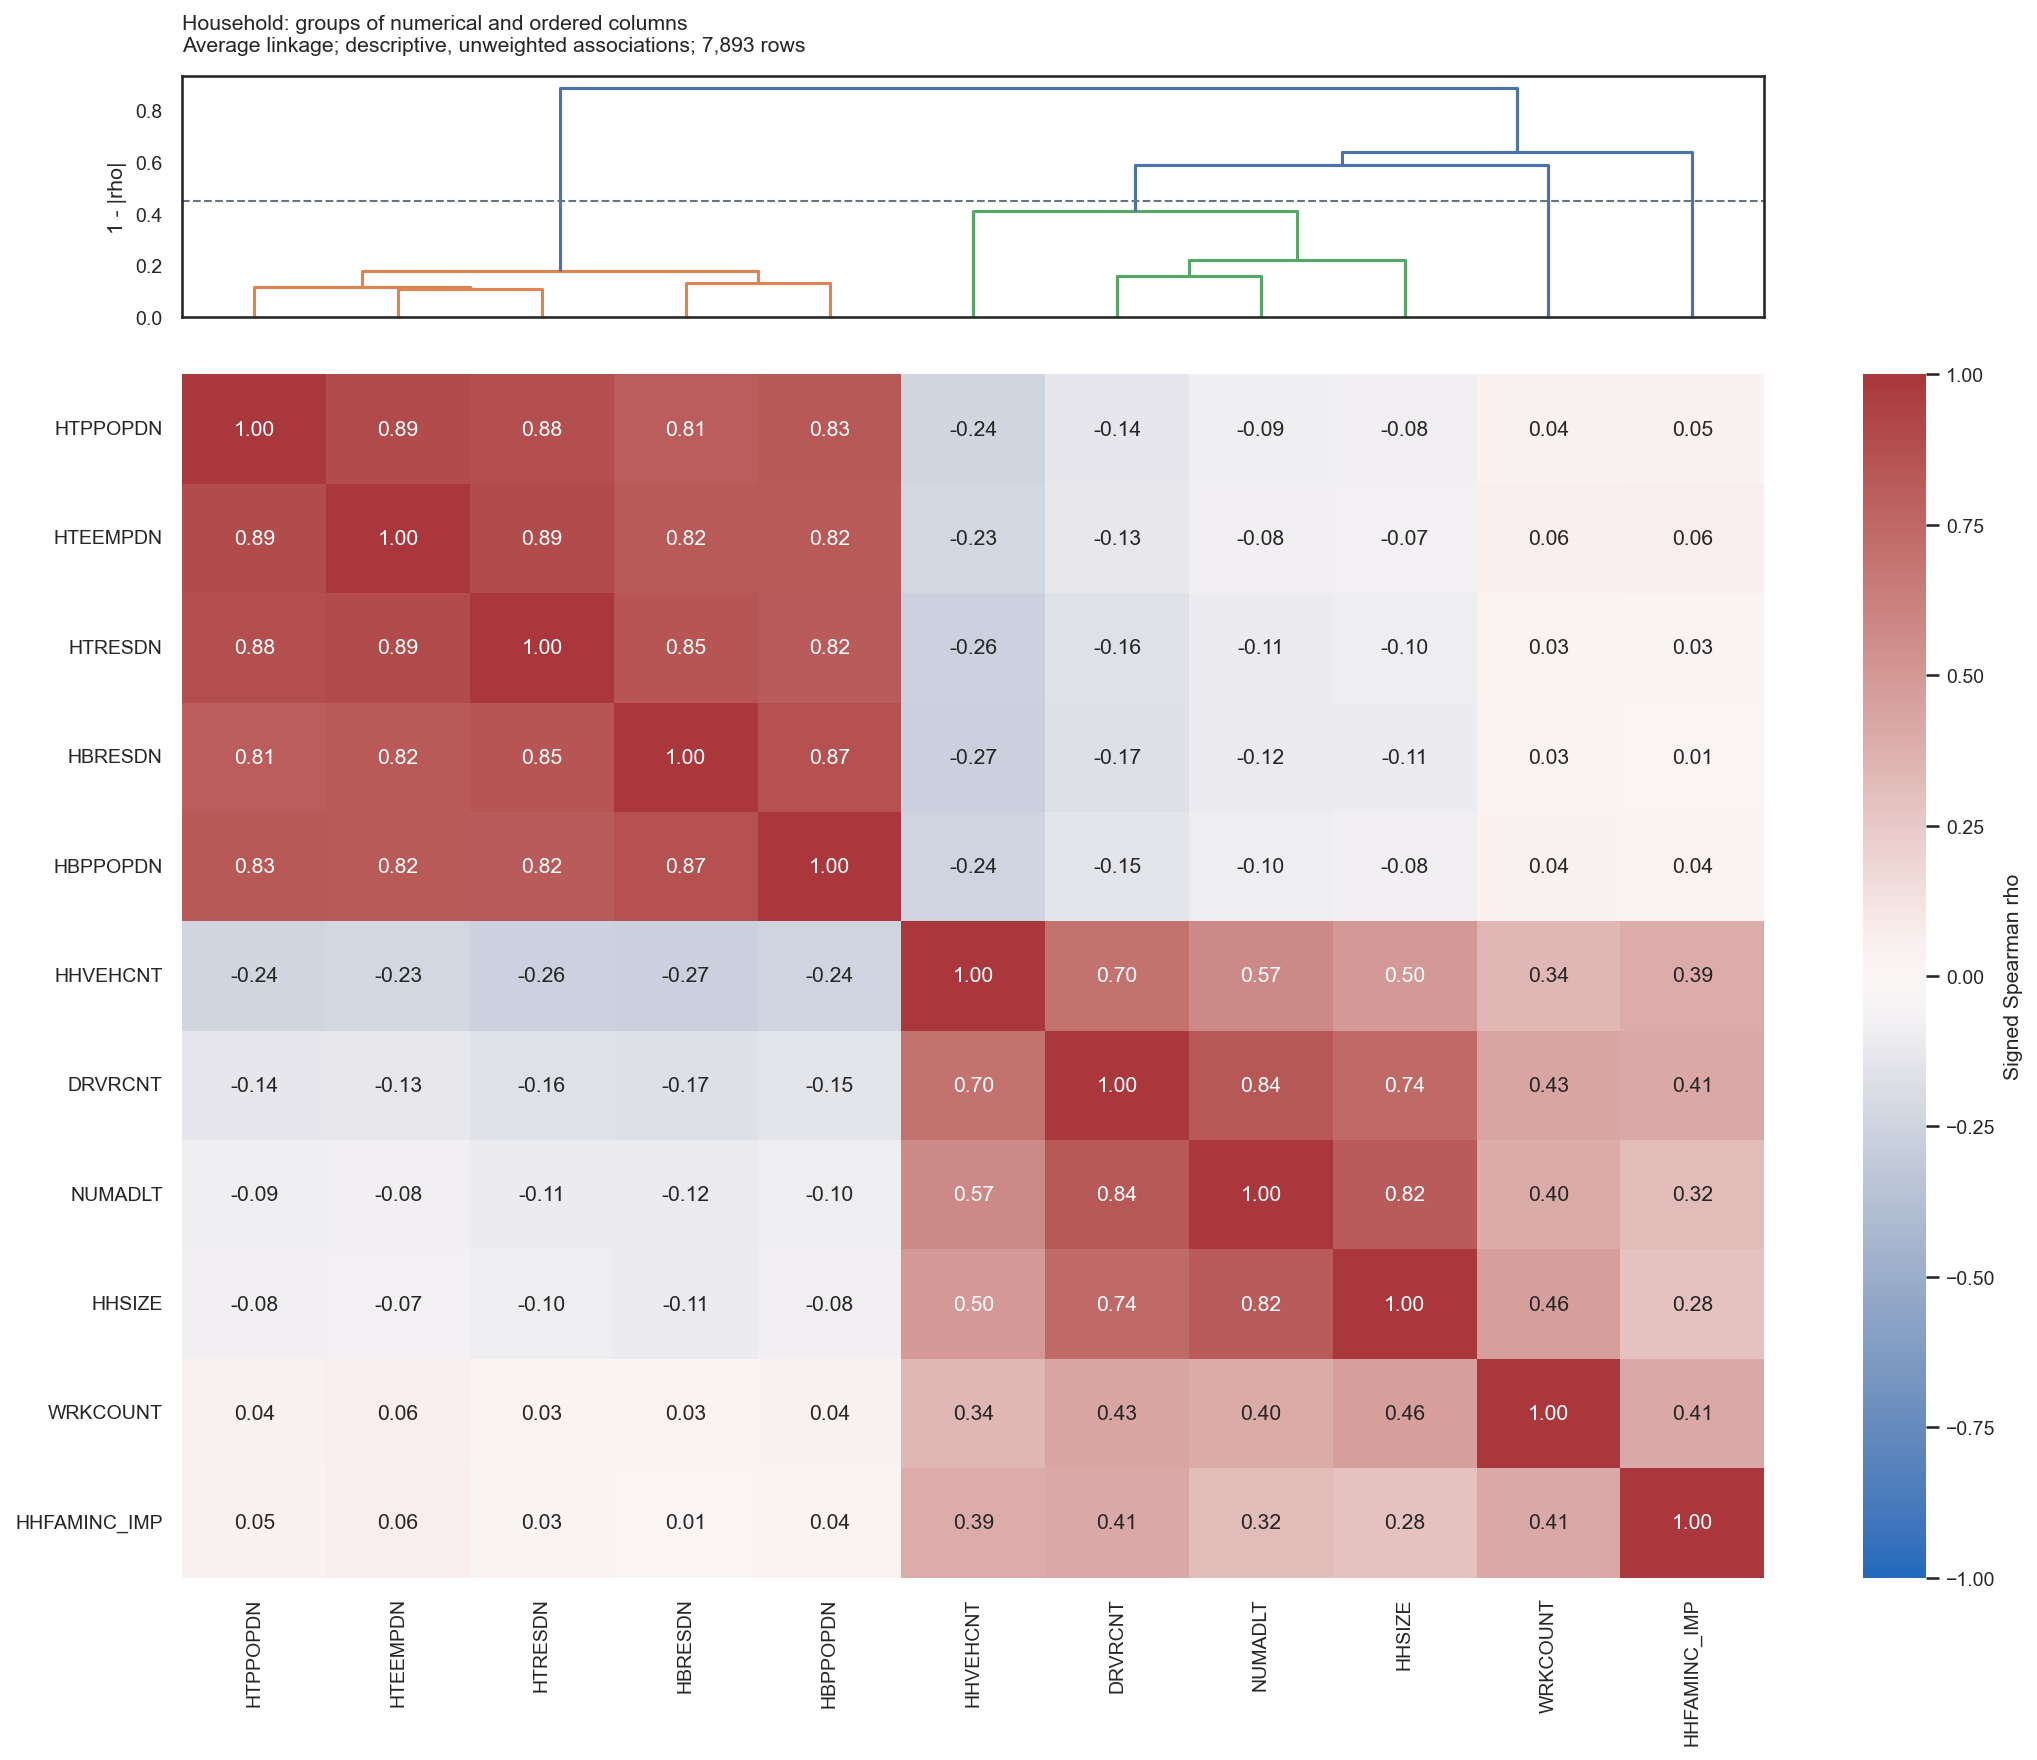

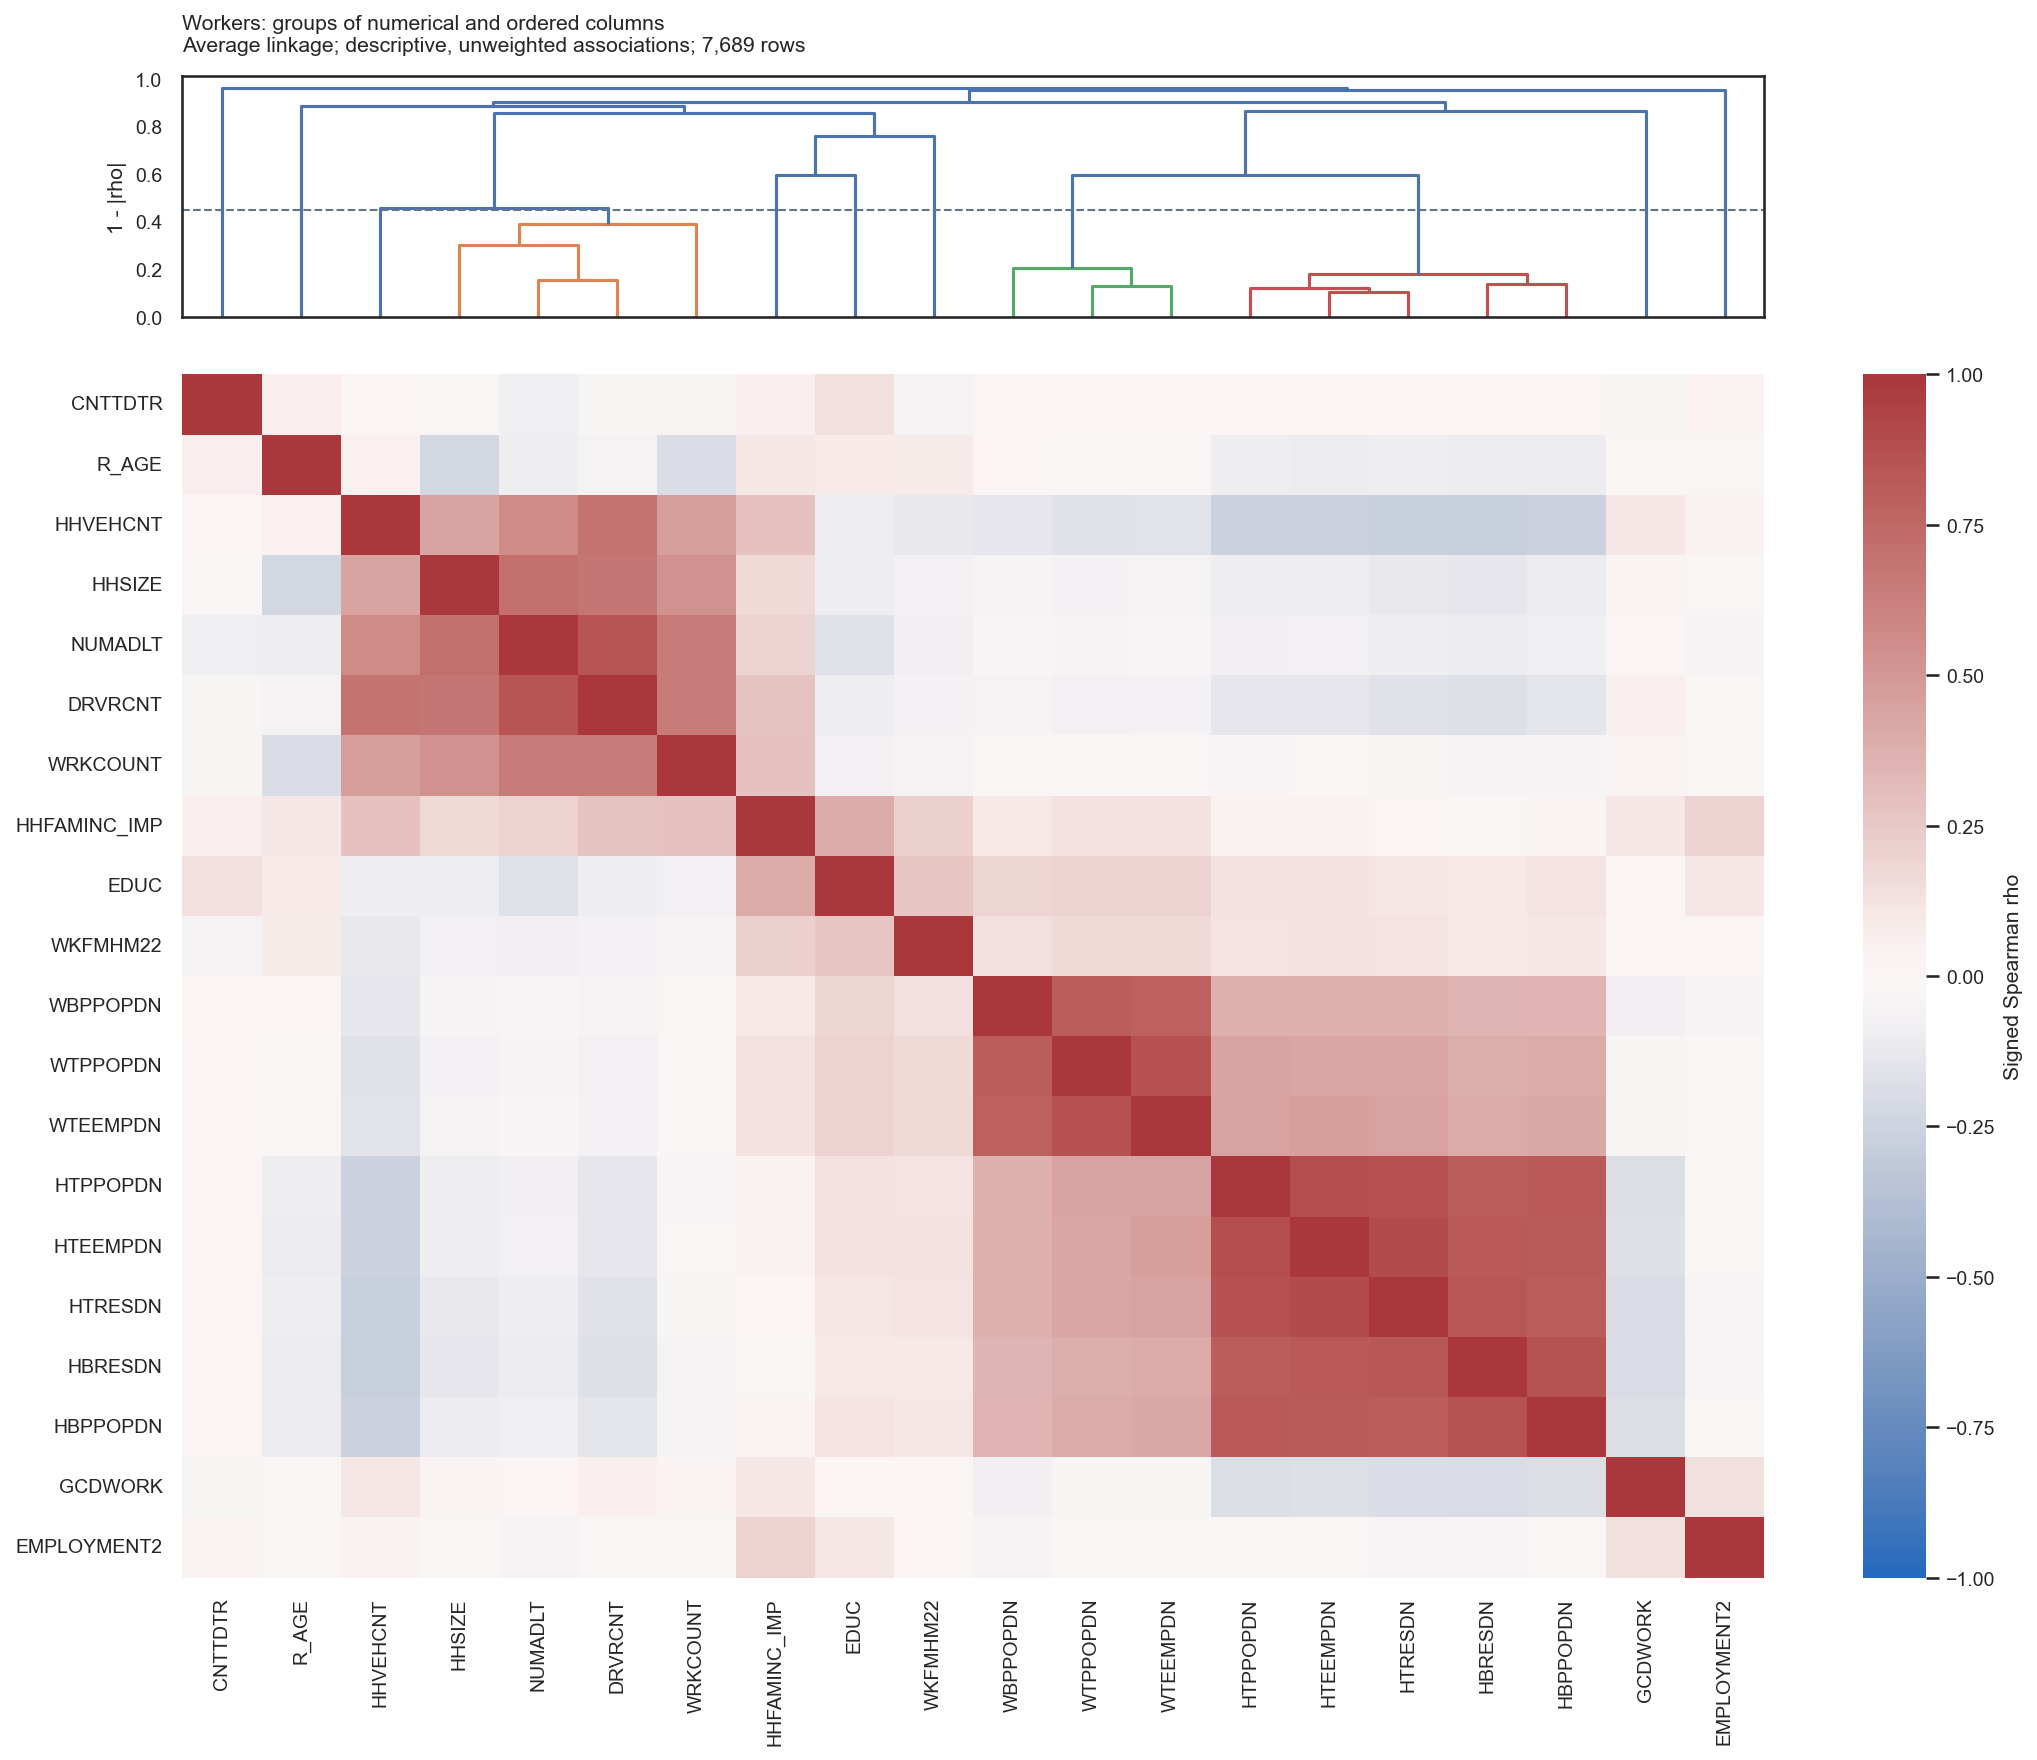

COMMUTE


,column,definition,analysis_type,valid_n,missing_pct,distinct,dominant_pct
0,HHSIZE,Total number of people in household,numeric/ordered,4269,0.000000,9,39.798548
1,NUMADLT,Count of adult household members at least 18 y...,numeric/ordered,4269,0.000000,7,61.419536
2,DRVRCNT,Number of drivers in the household,numeric/ordered,4269,0.000000,8,58.046381
3,WRKCOUNT,Count of workers in household,numeric/ordered,4269,0.000000,7,50.011712
4,HHVEHCNT,Total number of vehicles in household,numeric/ordered,4269,0.000000,11,45.584446
5,HBPPOPDN,Category of population density (persons per sq...,numeric/ordered,4250,0.445069,8,22.470588
6,HTPPOPDN,Category of population density (persons per sq...,numeric/ordered,4256,0.304521,8,22.720865
7,HBRESDN,Category of housing units per square mile in t...,numeric/ordered,4216,1.241509,8,21.845351
8,HTRESDN,Category of housing units per square mile in t...,numeric/ordered,4236,0.773015,8,22.261568
9,HTEEMPDN,Category of workers per square mile in the cen...,numeric/ordered,4247,0.515343,8,21.803626


HOUSEHOLD


,column,definition,analysis_type,valid_n,missing_pct,distinct,dominant_pct
0,HHSIZE,Total number of people in household,numeric/ordered,7893,0.000000,10,42.303307
1,NUMADLT,Count of adult household members at least 18 y...,numeric/ordered,7893,0.000000,8,56.087673
2,DRVRCNT,Number of drivers in the household,numeric/ordered,7893,0.000000,8,51.425314
3,WRKCOUNT,Count of workers in household,numeric/ordered,7893,0.000000,7,35.347777
4,HHVEHCNT,Total number of vehicles in household,numeric/ordered,7893,0.000000,13,40.529583
5,HBPPOPDN,Category of population density (persons per sq...,numeric/ordered,7855,0.481439,8,23.539147
6,HTPPOPDN,Category of population density (persons per sq...,numeric/ordered,7860,0.418092,8,21.272265
7,HBRESDN,Category of housing units per square mile in t...,numeric/ordered,7831,0.785506,8,21.006257
8,HTRESDN,Category of housing units per square mile in t...,numeric/ordered,7832,0.772837,8,21.284474
9,HTEEMPDN,Category of workers per square mile in the cen...,numeric/ordered,7837,0.709489,8,20.224576


WORKERS


,column,definition,analysis_type,valid_n,missing_pct,distinct,dominant_pct
0,HHSIZE,Total number of people in household,numeric/ordered,7689,0.000000,9,39.016777
1,NUMADLT,Count of adult household members at least 18 y...,numeric/ordered,7689,0.000000,8,61.048251
2,DRVRCNT,Number of drivers in the household,numeric/ordered,7689,0.000000,8,58.317076
3,WRKCOUNT,Count of workers in household,numeric/ordered,7689,0.000000,6,51.671219
4,HHVEHCNT,Total number of vehicles in household,numeric/ordered,7689,0.000000,12,44.882299
5,HBPPOPDN,Category of population density (persons per sq...,numeric/ordered,7650,0.507218,8,23.725490
6,HTPPOPDN,Category of population density (persons per sq...,numeric/ordered,7661,0.364157,8,21.498499
7,HBRESDN,Category of housing units per square mile in t...,numeric/ordered,7612,1.001431,8,21.334735
8,HTRESDN,Category of housing units per square mile in t...,numeric/ordered,7630,0.767330,8,21.808650
9,HTEEMPDN,Category of workers per square mile in the cen...,numeric/ordered,7643,0.598257,8,20.711762


In [7]:
for name in ['household','workers']:
    display(Image(filename=str(OUT / f'{name}_column_clusters.png')))
for name in samples:
    print(name.upper())
    display(samples[name]['quality'])

## Limits and next steps

- Commute mode counts are 4,062 car, 77 public transport and 130 active travel. Repeated trips are not independent; final modelling needs household/person dependence and appropriate survey design. Avoid large models for rare categories.
- Keep household members together in predictive train/test splits.
- Use trip, person or household weights consistent with the question and travel-day scope. None of the exploratory correlations above is weighted.
- Telework is four ordered categories, not an exact day count. Do not interpret its code with ordinary linear regression as days.
- Typical telework frequency does not identify telework on the survey day. The observed rho with daily trips is only -0.062.
- Choose representative density and composition columns; do not automatically keep every correlated field or mechanically discard all but one.
- Review zeros, missing locations and outliers before fitting duration/distance models. The largest observed duration is 950 minutes.
- Equal-person sensitivity for stable attributes is exported; it is not an inferential correction. Cut sensitivity is descriptive and not proof of stable latent constructs.

The standalone HTML report contains readable research-question assessments, definitions, and these figures. Detailed CSV outputs retain all pair counts and column memberships.

In [8]:
display(pd.Series(summary['mode_counts'], name='Trips').to_frame())
display(pd.Series(summary['telework_counts'], name='Workers by telework category').to_frame())
sensitivity = pd.read_csv(OUT / 'commute_equal_person_sensitivity.csv')
print('Largest |rho change| with one row per commuter for stable attributes:',
      round((sensitivity.trip_rho - sensitivity.one_person_rho).abs().max(), 3))
print('HTML report:', OUT / 'NHTS_2022_research_directions.html')

,Trips
car,4062
active_travel,130
public_transport,77


,Workers by telework category
1,4279
2,1117
3,609
4,1684


Largest |rho change| with one row per commuter for stable attributes: 0.021
HTML report: D:\StatProject\research_directions\NHTS_2022_research_directions.html
